# Klasifikasi Pembatalan Pemesanan Hotel (Hotel Booking Demand)

Notebook ini membangun model **Decision Tree** untuk memprediksi apakah sebuah pemesanan hotel akan **dibatalkan** (`is_canceled = 1`) atau **tidak dibatalkan** (`is_canceled = 0`).

Setiap cell kode diikuti penjelasan singkat: apa fungsi tiap perintah dan apa tujuan cell tersebut.

In [1]:
# Mengimpor pustaka yang diperlukan untuk analisis dan visualisasi data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset hotel_bookings.csv ke dalam DataFrame
df = pd.read_csv('hotel_bookings.csv')

# Melihat ukuran dataset (jumlah baris dan kolom)
print("Ukuran Dataset (Baris, Kolom):", df.shape)

# Menampilkan 5 baris pertama dataset
display(df.head())

Ukuran Dataset (Baris, Kolom): (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


- import pandas as pd — Mengimpor Pandas untuk membaca, mengolah, dan menganalisis data berbentuk tabel. pd merupakan nama singkatnya.
- import numpy as np — Mengimpor NumPy untuk operasi numerik.
- import matplotlib.pyplot as plt — Mengimpor Matplotlib untuk membuat grafik dan visualisasi.
- import seaborn as sns — Mengimpor Seaborn untuk membuat grafik statistik, termasuk heatmap.
- pd.read_csv('hotel_bookings.csv') — Membaca file CSV menjadi DataFrame bernama df. DataFrame adalah tabel yang terdiri dari baris dan kolom.
- df.shape — Menampilkan ukuran dataset dalam format (jumlah_baris, jumlah_kolom).
- df.head() — Menampilkan lima baris pertama untuk melihat gambaran isi data.
- display() — Menampilkan tabel secara rapi di notebook.

Tujuan cell: Menyiapkan library yang dibutuhkan, memuat dataset pemesanan hotel, dan melihat ukuran serta contoh isinya.

In [2]:
# 1. Melihat informasi detail tipe data setiap kolom
print("--- Informasi Dataset ---")
df.info()

# 2. Mengecek apakah ada baris data yang duplikat
print("\nJumlah Data Duplikat:", df.duplicated().sum())

# 3. Mengecek kolom yang memiliki nilai kosong (missing value)
print("\n--- Kolom yang Memiliki Missing Value ---")
missing = df.isnull().sum()
display(missing[missing > 0])

--- Informasi Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  m

children         4
country        488
agent        16340
company     112593
dtype: int64

- df.info() — Menampilkan nama kolom, jumlah data yang terisi, tipe data, dan penggunaan memori.
- df.duplicated().sum() — Menghitung jumlah baris yang isinya sama persis dengan baris lain.
- df.isnull().sum() — Menghitung banyaknya nilai kosong pada setiap kolom.
- missing[missing > 0] — Memfilter agar hanya kolom yang memiliki nilai kosong yang ditampilkan.

Dari hasil ini terlihat kolom yang perlu dibersihkan, yaitu children, country, agent, dan company. Kolom company memiliki nilai kosong paling banyak.

Tujuan cell: Memahami kondisi awal dataset sebelum dibersihkan, yaitu tipe data, data duplikat, dan nilai kosong.

--- Jumlah Data per Kelas ---
is_canceled
0    75166
1    44224
Name: count, dtype: int64

--- Persentase per Kelas (%) ---
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


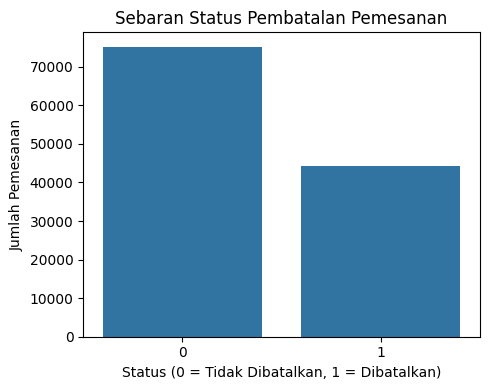

In [3]:
# 1. Melihat jumlah dan persentase tiap kelas pada target (is_canceled)
print("--- Jumlah Data per Kelas ---")
print(df['is_canceled'].value_counts())
print("\n--- Persentase per Kelas (%) ---")
print((df['is_canceled'].value_counts(normalize=True) * 100).round(2))

# 2. Membuat grafik sebaran kelas target
plt.figure(figsize=(5, 4))
sns.countplot(x='is_canceled', data=df)
plt.title('Sebaran Status Pembatalan Pemesanan')
plt.xlabel('Status (0 = Tidak Dibatalkan, 1 = Dibatalkan)')
plt.ylabel('Jumlah Pemesanan')
plt.tight_layout()
plt.show()

- df['is_canceled'] — Mengambil kolom target, yaitu status pembatalan (1 = dibatalkan, 0 = tidak dibatalkan).
- value_counts() — Menghitung jumlah data pada setiap kelas.
- value_counts(normalize=True) * 100 — Menghitung proporsi setiap kelas dalam persen.
- .round(2) — Membulatkan angka menjadi dua angka di belakang koma.
- plt.figure(figsize=(5, 4)) — Menentukan ukuran grafik.
- sns.countplot(x='is_canceled', data=df) — Membuat grafik batang yang menunjukkan jumlah data tiap kelas.
- plt.title(), plt.xlabel(), plt.ylabel() — Memberi judul dan nama sumbu.
- plt.tight_layout() — Merapikan tata letak agar tulisan tidak terpotong.
- plt.show() — Menampilkan grafik.

Dari hasil ini terlihat bahwa pemesanan yang tidak dibatalkan lebih banyak daripada yang dibatalkan, sehingga dataset tidak sepenuhnya seimbang.

Tujuan cell: Mengetahui sebaran kelas target karena hal ini memengaruhi cara membaca hasil evaluasi model.

In [4]:
# Membersihkan Missing Values (Data Kosong)
# fillna(nilai) mengisi sel yang kosong (NaN) dengan nilai yang ditentukan

# Kolom 'children' (jumlah anak): data kosong dianggap tidak membawa anak, diisi 0
df['children'] = df['children'].fillna(0)

# Kolom 'country' (negara asal tamu): data kosong diberi label 'Unknown'
df['country'] = df['country'].fillna('Unknown')

# Kolom 'agent' (ID agen travel): kosong berarti tidak memesan lewat agen, diisi 0
df['agent'] = df['agent'].fillna(0)

# Kolom 'company' (ID perusahaan): kosong berarti bukan pemesanan perusahaan, diisi 0
df['company'] = df['company'].fillna(0)

# Mengecek kembali total data kosong yang tersisa
print("Sisa Missing Values setelah dibersihkan:", df.isnull().sum().sum())

Sisa Missing Values setelah dibersihkan: 0


- df['kolom'].fillna(nilai) — Mengganti nilai kosong pada kolom tersebut dengan nilai yang ditentukan.
- df['kolom'] = ... — Menyimpan hasil penggantian kembali ke kolom pada dataset.
- children diisi 0 karena data kosong dianggap berarti tidak ada tamu anak-anak.
- country diisi 'Unknown' karena negara asal tamu tidak diketahui.
- agent dan company diisi 0 karena kosong berarti pemesanan tidak melalui agen atau perusahaan.
- df.isnull().sum().sum() — sum() pertama menjumlahkan nilai kosong per kolom, sum() kedua menjumlahkan semua kolom menjadi satu angka total.

Hasil akhirnya 0, artinya tidak ada lagi nilai kosong pada dataset.

Tujuan cell: Mengisi semua data yang kosong supaya dataset lengkap dan siap diproses oleh algoritma machine learning.

In [5]:
# Mengimpor LabelEncoder dari scikit-learn
from sklearn.preprocessing import LabelEncoder

# Membuat salinan dataframe agar data asli tetap aman
df_model = df.copy()

# Daftar kolom berformat teks yang akan diubah menjadi angka
categorical_columns = ['hotel', 'market_segment', 'distribution_channel',
                       'reserved_room_type', 'assigned_room_type', 'deposit_type',
                       'customer_type', 'arrival_date_month']

# Mengubah teks menjadi angka untuk setiap kolom pada daftar
for col in categorical_columns:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col].astype(str))

# Menampilkan contoh hasil encoding
print("Berhasil! Semua kolom teks sudah diubah menjadi angka.")
display(df_model[categorical_columns].head())

Berhasil! Semua kolom teks sudah diubah menjadi angka.


,hotel,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,arrival_date_month
0,1,3,1,2,2,0,2,5
1,1,3,1,2,2,0,2,5
2,1,3,1,0,2,0,2,5
3,1,2,0,0,0,0,2,5
4,1,6,3,0,0,0,2,5


- LabelEncoder — Alat dari scikit-learn untuk mengubah data teks (kategori) menjadi angka.
- df.copy() — Membuat salinan dataset. Perubahan pada df_model tidak mengubah df.
- categorical_columns — Daftar kolom yang berisi teks atau kategori.
- for col in categorical_columns: — Menjalankan perintah di bawahnya untuk setiap kolom dalam daftar.
- LabelEncoder() — Membuat objek encoder baru untuk setiap kolom.
- astype(str) — Menyeragamkan isi kolom menjadi teks.
- fit_transform() — Mempelajari semua kategori pada kolom, lalu mengubahnya menjadi angka (0, 1, 2, dan seterusnya).

Contoh: pada kolom hotel, "City Hotel" menjadi 0 dan "Resort Hotel" menjadi 1.

Tujuan cell: Mengubah kolom teks menjadi angka karena algoritma machine learning hanya dapat memproses data numerik.

In [6]:
# 1. Menentukan Variabel Fitur (X) / Prediktor
features = ['hotel', 'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
            'adults', 'children', 'is_repeated_guest', 'previous_cancellations',
            'booking_changes', 'adr']

X = df_model[features]

# 2. Menentukan Variabel Target (y)
y = df_model['is_canceled']

# 3. Menampilkan dimensi X dan y serta 5 baris pertama X
print("Dimensi Fitur (X):", X.shape)
print("Dimensi Target (y):", y.shape)

print("\n--- Contoh Data Fitur (X) ---")
display(X.head())

Dimensi Fitur (X): (119390, 10)
Dimensi Target (y): (119390,)

--- Contoh Data Fitur (X) ---


,hotel,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,is_repeated_guest,previous_cancellations,booking_changes,adr
0,1,342,0,0,2,0.0,0,0,3,0.0
1,1,737,0,0,2,0.0,0,0,4,0.0
2,1,7,0,1,1,0.0,0,0,0,75.0
3,1,13,0,1,1,0.0,0,0,0,75.0
4,1,14,0,2,2,0.0,0,0,0,98.0


Pada machine learning, data dibagi menjadi dua bagian utama:
- X adalah fitur atau variabel input yang digunakan model untuk mempelajari pola.
- y adalah target atau label yang ingin diprediksi.

Dalam notebook ini, targetnya adalah is_canceled (1 = dibatalkan, 0 = tidak dibatalkan).

Fitur yang digunakan:
- hotel — jenis hotel (City Hotel atau Resort Hotel).
- lead_time — jarak hari antara tanggal pemesanan dan tanggal kedatangan.
- stays_in_weekend_nights dan stays_in_week_nights — jumlah malam menginap di akhir pekan dan hari kerja.
- adults dan children — jumlah tamu dewasa dan anak-anak.
- is_repeated_guest — apakah tamu pernah menginap sebelumnya.
- previous_cancellations — jumlah pembatalan sebelumnya.
- booking_changes — jumlah perubahan pada pemesanan.
- adr — rata-rata tarif harian (Average Daily Rate).

Perintah X.shape dan y.shape menampilkan ukuran fitur dan target, sedangkan display(X.head()) menampilkan lima contoh data fitur.

Tujuan cell: Menentukan informasi yang digunakan untuk memprediksi pembatalan dan label yang ingin dihasilkan.

In [7]:
from sklearn.model_selection import train_test_split

# Membagi data dengan porsi 80% untuk training dan 20% untuk testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Menampilkan informasi jumlah data setelah dibagi
print("Jumlah Data Training (Latih) :", len(X_train))
print("Jumlah Data Testing (Uji)    :", len(X_test))
print("Persentase Data Latih        :", round((len(X_train) / len(X)) * 100, 2), "%")

Jumlah Data Training (Latih) : 95512
Jumlah Data Testing (Uji)    : 23878
Persentase Data Latih        : 80.0 %


- train_test_split — Fungsi untuk membagi dataset menjadi data latih dan data uji.
- X dan y — Data fitur dan target.
- test_size=0.20 — Menetapkan 20% data untuk pengujian dan sisanya 80% untuk pelatihan.
- random_state=42 — Membuat pembagian data selalu sama setiap kali dijalankan, sehingga hasil dapat diulang.
- X_train berisi fitur untuk melatih model, sedangkan X_test berisi fitur untuk menguji model.
- y_train berisi label yang dipelajari model, sedangkan y_test berisi label sebenarnya untuk dibandingkan dengan prediksi.
- len() — Menghitung jumlah baris. Jumlah data latih dibagi total data lalu dikali 100 menghasilkan persentase data latih.

Tujuan cell: Memisahkan data untuk pembelajaran dan evaluasi agar model diuji pada data yang tidak digunakan saat pelatihan.

In [8]:
from sklearn.tree import DecisionTreeClassifier

# 1. Membuat model Decision Tree
model = DecisionTreeClassifier(random_state=42)

# 2. Melatih model menggunakan data training (X_train dan y_train)
model.fit(X_train, y_train)

print("Model Decision Tree Berhasil Dilatih!")
print("Kedalaman pohon :", model.get_depth())
print("Jumlah daun     :", model.get_n_leaves())

Model Decision Tree Berhasil Dilatih!
Kedalaman pohon : 48
Jumlah daun     : 20987


- DecisionTreeClassifier — Algoritma klasifikasi yang membuat pohon keputusan berupa rangkaian pertanyaan ya/tidak berdasarkan nilai fitur, misalnya "apakah lead_time lebih dari 100 hari?".
- random_state=42 — Membuat hasil pelatihan konsisten setiap kali dijalankan.
- model.fit(X_train, y_train) — Membuat model mempelajari hubungan antara fitur pemesanan (X_train) dan status pembatalannya (y_train).
- model.get_depth() — Menampilkan kedalaman pohon, yaitu jumlah tingkat pertanyaan terpanjang.
- model.get_n_leaves() — Menampilkan jumlah daun, yaitu ujung pohon tempat keputusan akhir diambil.

Karena kedalaman pohon tidak dibatasi, pohon tumbuh sangat dalam sampai hampir menghafal data latih. Hal ini akan terlihat pada perbandingan akurasi di tahap evaluasi.

Tujuan cell: Melatih model agar dapat memperkirakan apakah suatu pemesanan hotel akan dibatalkan atau tidak.

Akurasi Data Latih : 97.96%
Akurasi Data Uji   : 77.89%

--- Laporan Klasifikasi ---
              precision    recall  f1-score   support

           0       0.82      0.82      0.82     14907
           1       0.71      0.71      0.71      8971

    accuracy                           0.78     23878
   macro avg       0.76      0.76      0.76     23878
weighted avg       0.78      0.78      0.78     23878



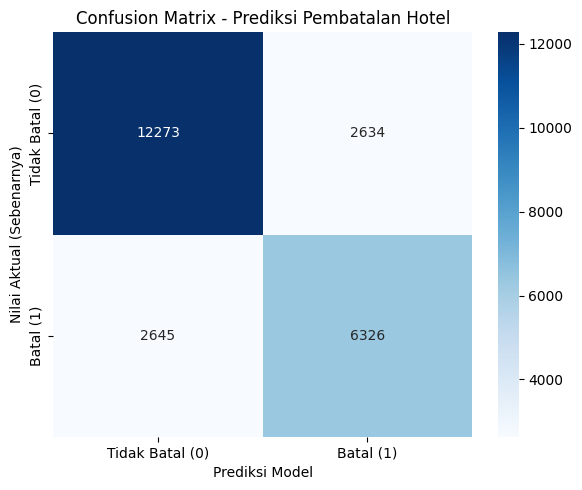

In [9]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Melakukan prediksi pada data testing
y_pred = model.predict(X_test)

# 2. Menghitung akurasi pada data latih dan data uji
train_accuracy = accuracy_score(y_train, model.predict(X_train))
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi Data Latih : {train_accuracy * 100:.2f}%")
print(f"Akurasi Data Uji   : {accuracy * 100:.2f}%\n")

# 3. Menampilkan Laporan Klasifikasi lengkap
print("--- Laporan Klasifikasi ---")
print(classification_report(y_test, y_pred, zero_division=0))

# 4. Membuat visualisasi Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Tidak Batal (0)', 'Batal (1)'],
    yticklabels=['Tidak Batal (0)', 'Batal (1)']
)
plt.title('Confusion Matrix - Prediksi Pembatalan Hotel')
plt.xlabel('Prediksi Model')
plt.ylabel('Nilai Aktual (Sebenarnya)')
plt.tight_layout()
plt.show()

- classification_report, accuracy_score, dan confusion_matrix — Fungsi untuk mengukur performa model.
- model.predict(X_test) — Menghasilkan prediksi untuk data testing. Hasilnya disimpan pada y_pred.
- accuracy_score(y_test, y_pred) — Menghitung persentase prediksi yang benar dibanding jumlah seluruh data uji.
- f"{accuracy * 100:.2f}%" — Menampilkan akurasi dalam persen dengan dua angka di belakang koma.

Akurasi data latih jauh lebih tinggi daripada akurasi data uji. Selisih yang besar ini menandakan model overfitting, yaitu terlalu menghafal data latih sehingga kurang baik pada data baru.

Laporan klasifikasi menampilkan beberapa metrik:
- Precision: Seberapa banyak prediksi suatu kelas yang benar.
- Recall: Seberapa banyak data aktual suatu kelas yang berhasil ditemukan model.
- F1-score: Gabungan precision dan recall.
- Support: Jumlah data aktual pada kelas tersebut.
- zero_division=0 mengatur nilai yang ditampilkan jika suatu metrik tidak dapat dihitung.

Confusion matrix:
- sns.heatmap(...) menampilkan matriks dalam bentuk kotak-kotak berwarna.
- annot=True menampilkan angka pada setiap kotak, fmt='d' menampilkannya sebagai bilangan bulat, dan cmap='Blues' memilih gradasi warna biru.
- Sumbu horizontal adalah prediksi model, sumbu vertikal adalah nilai aktual.

Cara membaca confusion matrix:
- Kotak kiri atas: pemesanan tidak dibatalkan yang diprediksi benar tidak dibatalkan.
- Kotak kanan bawah: pemesanan dibatalkan yang diprediksi benar dibatalkan.
- Kotak kanan atas dan kiri bawah: prediksi yang salah.
Semakin besar angka pada diagonal (kiri atas ke kanan bawah), semakin baik model.

Tujuan cell: Mengukur seberapa baik model memprediksi pembatalan pada data yang belum pernah dilihat.

In [10]:
# Membuat contoh pemesanan baru untuk diprediksi oleh model
sample_booking = pd.DataFrame({
    'hotel': [0],                       # 0 = City Hotel, 1 = Resort Hotel
    'lead_time': [120],
    'stays_in_weekend_nights': [1],
    'stays_in_week_nights': [2],
    'adults': [2],
    'children': [0],
    'is_repeated_guest': [0],
    'previous_cancellations': [0],
    'booking_changes': [0],
    'adr': [100.0]
})

# Melakukan prediksi status pembatalan
prediksi = model.predict(sample_booking)
print("Hasil Prediksi:", "DIBATALKAN" if prediksi[0] == 1 else "TIDAK DIBATALKAN")

Hasil Prediksi: DIBATALKAN


Kode ini membuat DataFrame berisi satu contoh pemesanan yang ingin diprediksi.

Setiap kolom harus sama dengan fitur yang digunakan ketika model dilatih. Contoh ini berisi pemesanan City Hotel dengan lead time 120 hari, menginap 1 malam akhir pekan dan 2 malam hari kerja, 2 tamu dewasa tanpa anak, bukan tamu berulang, belum pernah membatalkan, tanpa perubahan pemesanan, dan tarif harian 100.

- model.predict(sample_booking) — Memasukkan data pemesanan ke model untuk diprediksi.
- prediksi[0] — Mengambil hasil prediksi pertama karena contoh hanya berisi satu pemesanan.
- Jika hasilnya 1, pemesanan diprediksi dibatalkan. Jika 0, diprediksi tidak dibatalkan.

Hasil prediksi bergantung pada model yang berhasil dilatih. Ini hanya contoh penggunaan model, bukan kepastian bahwa pemesanan tersebut benar-benar akan dibatalkan.

Tujuan cell: Memperlihatkan cara menggunakan model yang sudah dilatih untuk memprediksi data pemesanan baru.